HOMEWORK 4

In [49]:
# Dependencies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import KFold

Getting the data

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


Data preparation

In [4]:
# Missing values
df.isnull().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


For missing values:

- Categorical features, replace them with 'NA'
- Numerical features, replace with 0.0

In [5]:
df[df.select_dtypes(include='object').columns] = df.select_dtypes(include='object').fillna('NA')

In [6]:
df[df.select_dtypes(include=np.number).columns] = df.select_dtypes(include=np.number).fillna(0.0)

In [7]:
# Missing values after imputation
df.isnull().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


Split data with homework code:

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [9]:

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [10]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

**Question 1: ROC AUC feature importance**

**Which numerical variable has the highest AUC?**

Answer: lead_score

In [11]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [12]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        new_auc = roc_auc_score(y_train, -df_train[col])
        print(col, "---> ", new_auc)
    else:
        print(col, "---> ", auc)

annual_income --->  0.6081977776250831
number_of_courses_viewed --->  0.7229894623989618
interaction_count --->  0.7649203047563227
lead_score --->  0.7882254810906102


**Question 2: Training the model**

**What's the AUC of this model on the validation dataset? (round to 3 digits)**

Answer: 0.732

In [13]:
features = categorical + numerical

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [14]:
y_pred = model.predict_proba(X_val)[:, 1]

In [15]:
model_auc = roc_auc_score(y_val, y_pred)
round(model_auc, 3)

np.float64(0.732)

**Question 3: Precision and Recall**

**At which threshold precision and recall curves intersect?**

Answer: 0.63

Precision and recall on all thresholds (homework: from 0.0 to 1.0 with step 0.01)

In [25]:
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

# Evaluation at each threshold
for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    tp = ((y_pred_binary == 1) & (y_val == 1)).sum()
    fp = ((y_pred_binary == 1) & (y_val == 0)).sum()
    fn = ((y_pred_binary == 0) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, precision, recall))

Plotting Precision and Recall at each Threshold

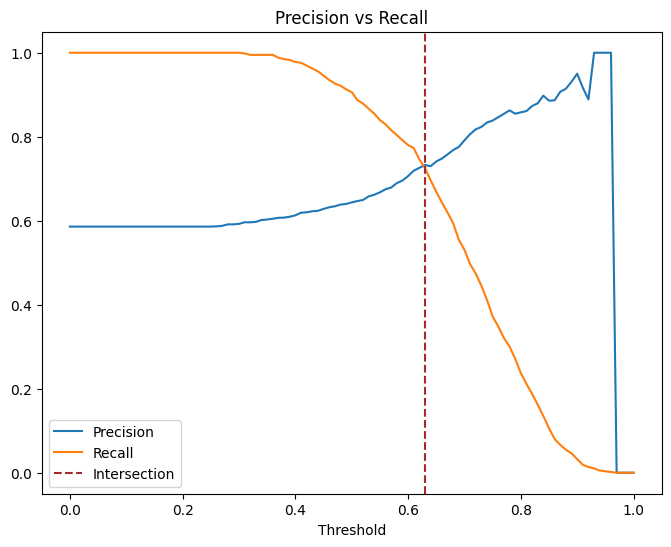

In [50]:
thresholds = [s[0] for s in scores]
precision = [s[1] for s in scores]
recall = [s[2] for s in scores]

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precision, label="Precision")
plt.plot(thresholds, recall, label="Recall")
plt.axvline(x=0.63, color="brown", linestyle="--", label="Intersection")

plt.xlabel("Threshold")
plt.title("Precision vs Recall")
plt.legend()
plt.show()

Threshold with the smallest absolute difference between precision and recall

In [35]:
t_intersection = 0
small_diff = 1000

for s in scores:
    t = s[0]  # Threshold
    p = s[1]  # Precision
    r = s[2]  # Recall

    if p == 0 and r == 0:
        continue

    diff = abs(p - r)

    if diff < small_diff:
        small_diff = diff
        t_intersection = t

# Intersection at:
print(round(t_intersection, 2))

0.63


**Question 4: F1 score**

**At which threshold F1 is maximal?**

Answer: 0.41

In [58]:
f1_scores = []
for t, p, r in scores:
    if (p + r) == 0:
        f1 = 0
    else:
        f1 = 2 * (p * r) / (p + r)
    f1_scores.append((t, f1))



best_t = 0.0
best_f1 = -1.0

for t, f1 in f1_scores:
    if f1 > best_f1:
        best_f1 = f1
        best_t = t
print(round(best_t,2)) # Threshold with max F1 score
print(best_f1) # Max F1 score

0.41
0.7576158940397352


**Question 5: 5-Fold CV**

**How large is standard deviation of the scores across different folds?**

Answer: 0.007

In [61]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    features = [c for c in df_full_train.columns if c != 'converted' and c != 'id']

    train_dicts = df_train[features].to_dict(orient='records')
    val_dicts = df_val[features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [64]:
print(round(np.std(scores),3))

0.007


**Question 6: Hyperparameter Tuning**

**Which C leads to the best mean ROC AUC?**

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

Answer: 0.001

In [73]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

C_values = [0.000001, 0.001, 1]

for C in C_values:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        features = [c for c in df_full_train.columns if c != 'converted' and c != 'id']

        train_dicts = df_train[features].to_dict(orient='records')
        val_dicts = df_val[features].to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    print(C, mean_auc, std_auc)

1e-06 0.6167342250714795 0.018669799234831475
0.001 0.7491721776030379 0.009996375455700753
1 0.7317269710972524 0.006853233151022138
